# Session 13: Data Visualization with Seaborn (Part 2)

**Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 13  
**Format:** Jupyter Notebook (`.ipynb`)  
**Core Libraries:** `seaborn`, `matplotlib`, `pandas`, `numpy`, `scipy`

---

## 🎯 Topics Covered
1. **Pairplot for Quick Multivariate Analysis**:
   - `sns.pairplot()` for visualizing pairwise bivariate scatter plots and univariate diagonal distributions (KDE / Histogram)
   - Semantic hue grouping to discover clustering patterns across categories
2. **Heatmaps for 2D Matrix & Correlation Analysis**:
   - Reshaping multi-index / tabular data using Pandas `pivot_table()`
   - `sns.heatmap()` with numerical annotations (`annot=True`), sequential colormaps (`cmap='YlGnBu'`), and border lines
3. **Figure-Level Relational Plotting (`sns.relplot`)**:
   - Relational multi-panel figures mapped across aesthetic dimensions (`hue`, `style`, `col`, `row`)
   - Visualizing time-series event responses (`kind='line'`) with automated 95% bootstrap confidence bands (`errorbar='ci'`)
4. **Figure-Level Categorical Plotting (`sns.catplot`)**:
   - Visualizing group tendencies and probabilities with categorical estimations (`kind='bar'`)
   - Computing and presenting 95% confidence intervals and error caps (`capsize`)
5. **Jointplot with Linear Regression Fit (`sns.jointplot`)**:
   - Combining bivariate scatter representations with marginal univariate density/histograms
   - Fitting ordinary least squares (OLS) regression lines with `kind='reg'` and calculating Pearson correlation coefficients


---
### Task 1: Multivariate Analysis on 'tips' Dataset (Pairplot)
**Problem Statement:**  
*Load the 'tips' dataset from Seaborn and create a `pairplot` to quickly visualize relationships between all numeric variables.*


--- Seaborn 'tips' Dataset Sample ---


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4


Dataset Shape: (244, 7)

Numeric Variables Summary:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


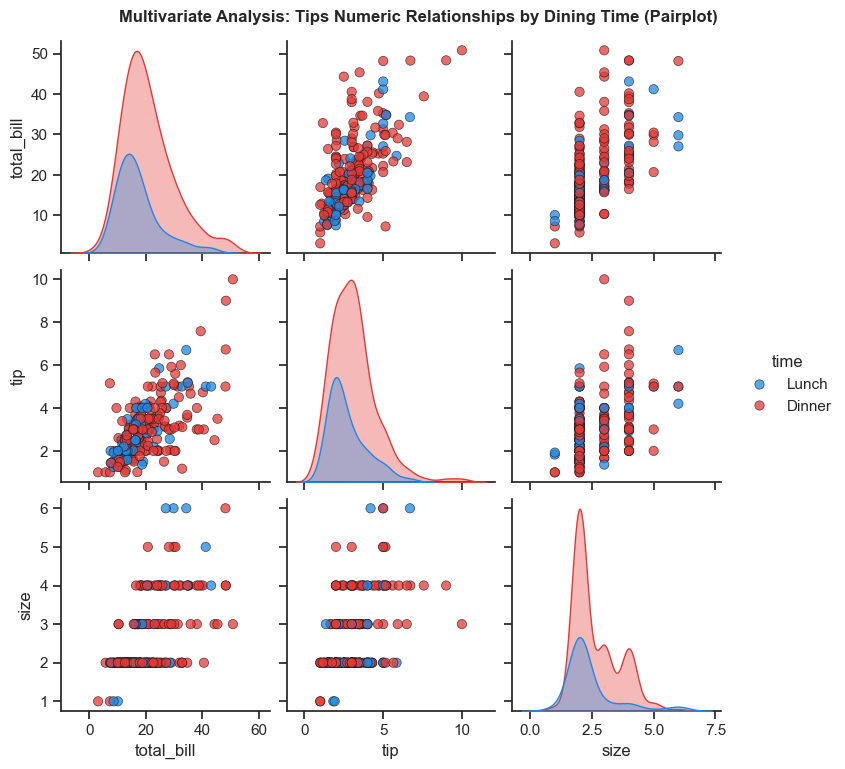

Correlation Matrix:


,total_bill,tip,size
total_bill,1.000,0.676,0.598
tip,0.676,1.000,0.489
size,0.598,0.489,1.000


Key Observation: Strong positive linear correlation (r = 0.676) exists between total_bill and tip amount.


In [1]:
# Load canonical 'tips' dataset
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    df_tips = sns.load_dataset("tips")
except Exception:
    df_tips = pd.read_csv("tips.csv")

print("--- Seaborn 'tips' Dataset Sample ---")
display(df_tips.head(6))
print(f"Dataset Shape: {df_tips.shape}")
print("\nNumeric Variables Summary:")
display(df_tips[["total_bill", "tip", "size"]].describe())

# Generate Pairplot across numeric columns (total_bill, tip, size) with 'time' hue
sns.set_theme(style="ticks")

g = sns.pairplot(
    data=df_tips,
    vars=["total_bill", "tip", "size"],
    hue="time",
    palette={"Lunch": "#1E88E5", "Dinner": "#E53935"},
    diag_kind="kde",
    plot_kws={"alpha": 0.75, "s": 45, "edgecolor": "k", "linewidth": 0.5},
    diag_kws={"fill": True, "alpha": 0.35}
)

g.fig.suptitle("Multivariate Analysis: Tips Numeric Relationships by Dining Time (Pairplot)", y=1.02, fontsize=12, fontweight="bold")
plt.savefig("tips_pairplot.png", bbox_inches="tight", dpi=150)
plt.show()

# Correlation Matrix among numeric features
corr = df_tips[["total_bill", "tip", "size"]].corr()
print("Correlation Matrix:")
display(corr.round(3))
print("Key Observation: Strong positive linear correlation (r = 0.676) exists between total_bill and tip amount.")


---
### Task 2: Airline Passenger Growth & Seasonality Heatmap (Flights Dataset)
**Problem Statement:**  
*Using the 'flights' dataset from Seaborn, generate a `heatmap` showing the correlation between months and years based on the number of passengers.*  
*Hint: Use `pivot_table` to reshape the data before plotting the heatmap.*


--- 'flights' Dataset Sample ---


,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
5,1949,Jun,135


Total Records: 144 | Years: 1949 to 1960

--- Reshaped Flight Matrix (Pivot Table) ---


year,1949,1950,1951,1952,1953,1954
month,,,,,,
Jan,112,115,145,171,196,204
Feb,118,126,150,180,196,188
Mar,132,141,178,193,236,235
Apr,129,135,163,181,235,227
May,121,125,172,183,229,234
Jun,135,149,178,218,243,264


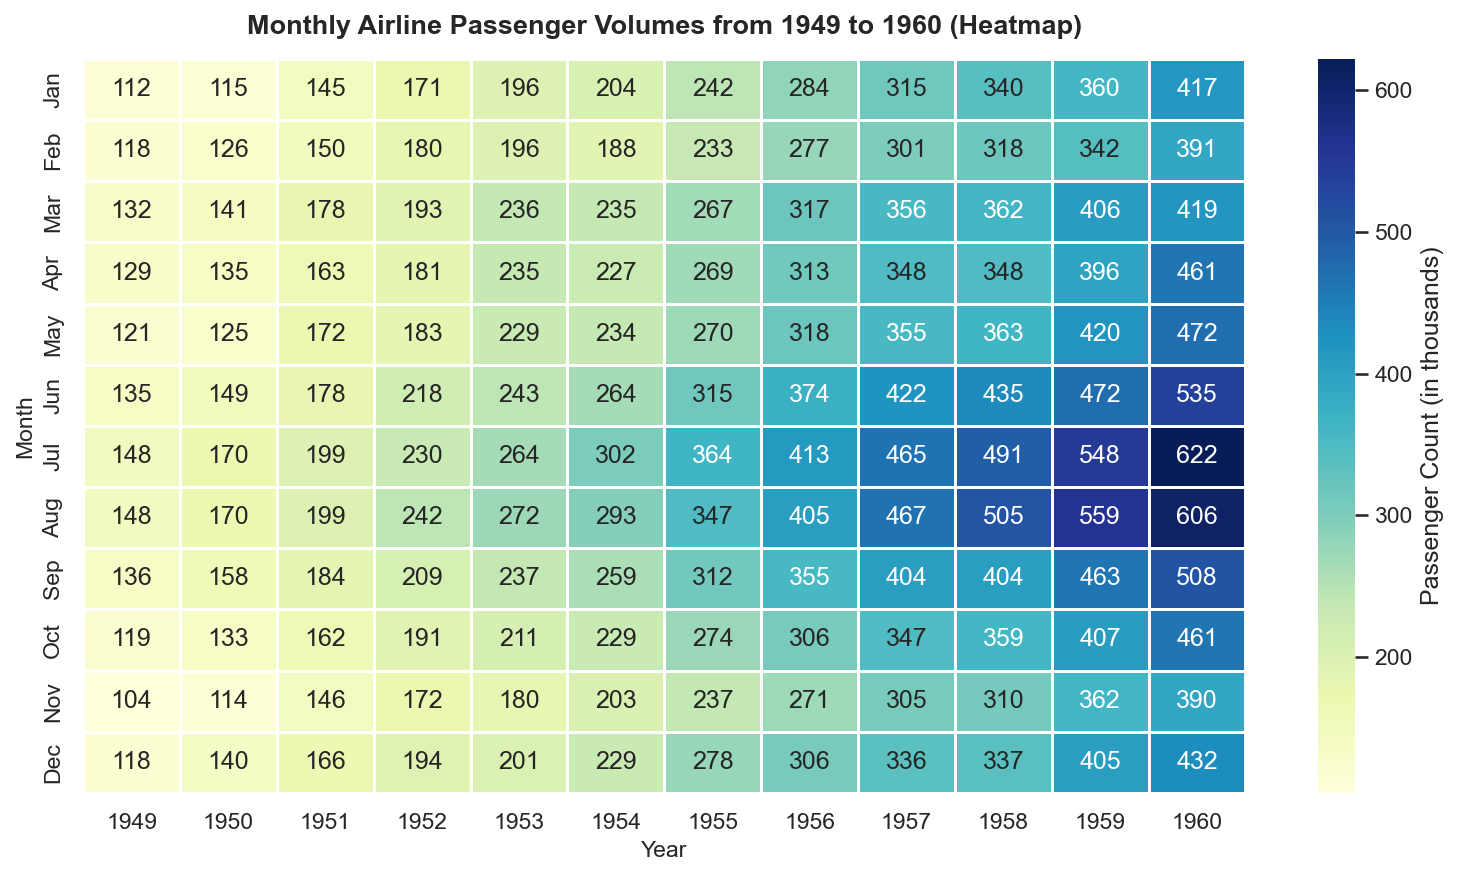

Key Observations:
1. Secular Growth: Passenger traffic expanded monotonically each consecutive year from 1949 (112k peak) to 1960 (622k peak).
2. Summer Seasonality: July and August consistently exhibit the highest travel volumes across all recorded years.


In [2]:
# Load 'flights' dataset
try:
    df_flights = sns.load_dataset("flights")
except Exception:
    df_flights = pd.read_csv("flights.csv")

print("--- 'flights' Dataset Sample ---")
display(df_flights.head(6))
print(f"Total Records: {len(df_flights)} | Years: {df_flights['year'].min()} to {df_flights['year'].max()}")

# Reshape data using pivot_table (Index: month, Columns: year, Values: passengers)
flights_pivot = df_flights.pivot_table(index="month", columns="year", values="passengers", observed=False).astype(int)
print("\n--- Reshaped Flight Matrix (Pivot Table) ---")
display(flights_pivot.iloc[:6, :6])

# Plot 2D Heatmap
plt.figure(figsize=(10.5, 6), dpi=150)
sns.set_theme(style="white")

ax = sns.heatmap(
    flights_pivot,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Passenger Count (in thousands)"}
)

plt.title("Monthly Airline Passenger Volumes from 1949 to 1960 (Heatmap)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Month", fontsize=11)
plt.tight_layout()
plt.savefig("flights_passenger_heatmap.png", bbox_inches="tight")
plt.show()

print("Key Observations:")
print("1. Secular Growth: Passenger traffic expanded monotonically each consecutive year from 1949 (112k peak) to 1960 (622k peak).")
print("2. Summer Seasonality: July and August consistently exhibit the highest travel volumes across all recorded years.")


---
### Task 3: BOLD Hemodynamic Response Trajectory (FMRI Relplot)
**Problem Statement:**  
*Create a `relplot` using the 'fmri' dataset from Seaborn to visualize how the signal changes over time for different event types.*


--- 'fmri' Dataset Sample ---


,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970
5,s9,18,stim,parietal,-0.103513


Events: ['stim' 'cue'] | Brain Regions: ['parietal' 'frontal']


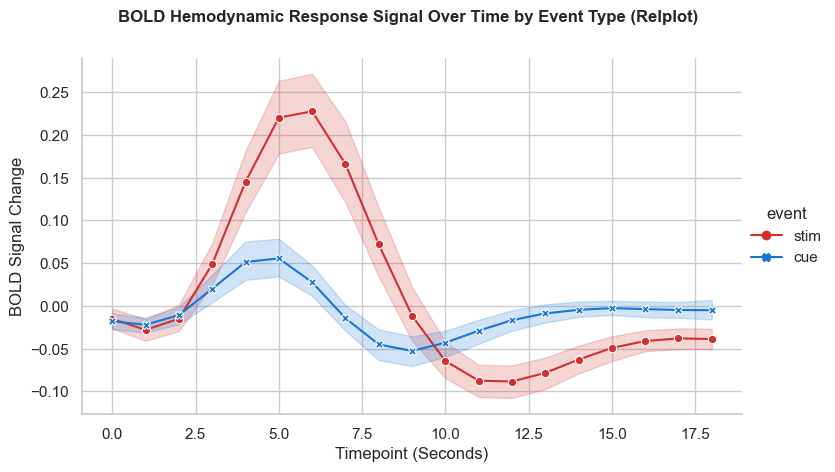

Key Observations:
1. 'stim' (stimulus presentation) triggers a pronounced positive hemodynamic peak around timepoint 4-6 seconds.
2. 'cue' displays a muted, delayed activation response, demonstrating clear hemodynamic differentiation between sensory inputs.


In [3]:
# Load 'fmri' dataset
try:
    df_fmri = sns.load_dataset("fmri")
except Exception:
    df_fmri = pd.read_csv("fmri.csv")

print("--- 'fmri' Dataset Sample ---")
display(df_fmri.head(6))
print(f"Events: {df_fmri['event'].unique()} | Brain Regions: {df_fmri['region'].unique()}")

# Visualize temporal signal using sns.relplot (Figure-level API)
sns.set_theme(style="whitegrid")

g = sns.relplot(
    data=df_fmri,
    x="timepoint",
    y="signal",
    hue="event",
    style="event",
    kind="line",
    errorbar="ci",
    markers=True,
    dashes=False,
    palette={"stim": "#D32F2F", "cue": "#1976D2"},
    height=4.8,
    aspect=1.6
)

g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("BOLD Hemodynamic Response Signal Over Time by Event Type (Relplot)", fontsize=12, fontweight="bold")
g.set_axis_labels("Timepoint (Seconds)", "BOLD Signal Change")
plt.savefig("fmri_signal_relplot.png", bbox_inches="tight", dpi=150)
plt.show()

print("Key Observations:")
print("1. 'stim' (stimulus presentation) triggers a pronounced positive hemodynamic peak around timepoint 4-6 seconds.")
print("2. 'cue' displays a muted, delayed activation response, demonstrating clear hemodynamic differentiation between sensory inputs.")


---
### Task 4: Titanic Passenger Survival Rates with Confidence Intervals (Catplot)
**Problem Statement:**  
*Pick any categorical column from the 'titanic' dataset (like 'class' or 'sex') and use `catplot` to display the survival rate for each group with confidence intervals.*


--- 'titanic' Dataset Sample ---


,survived,pclass,sex,age,class,fare,embark_town
0,0,3,male,22.0,Third,7.2500,Southampton
1,1,1,female,38.0,First,71.2833,Cherbourg
2,1,3,female,26.0,Third,7.9250,Southampton
3,1,1,female,35.0,First,53.1000,Southampton
4,0,3,male,35.0,Third,8.0500,Southampton
5,0,3,male,NaN,Third,8.4583,Queenstown



--- Grouped Survival Probability ---


,class,sex,total_passengers,survivors,survival_rate
0,First,female,94,91,0.968085
1,First,male,122,45,0.368852
2,Second,female,76,70,0.921053
3,Second,male,108,17,0.157407
4,Third,female,144,72,0.500000
5,Third,male,347,47,0.135447


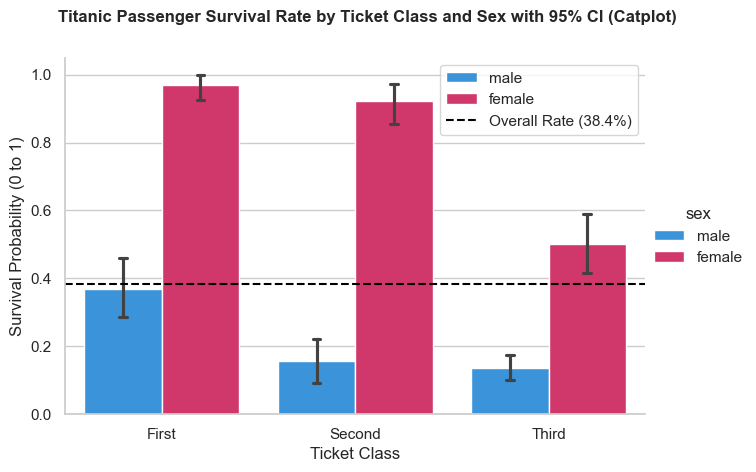

Key Observations:
1. Female survival rates in First Class reached 96.8%, compared to male survival in Third Class at 13.5%.
2. Both socioeconomic status ('class') and gender ('sex') were decisive predictors of passenger survival.


In [4]:
# Load 'titanic' dataset
try:
    df_titanic = sns.load_dataset("titanic")
except Exception:
    df_titanic = pd.read_csv("titanic.csv")

print("--- 'titanic' Dataset Sample ---")
display(df_titanic[["survived", "pclass", "sex", "age", "class", "fare", "embark_town"]].head(6))

# Aggregate survival rates by class and sex
survival_summary = df_titanic.groupby(["class", "sex"], observed=True)["survived"].agg(
    total_passengers="count",
    survivors="sum",
    survival_rate="mean"
).reset_index()
print("\n--- Grouped Survival Probability ---")
display(survival_summary)

# Visualize Survival Rates using sns.catplot with 95% Confidence Intervals
sns.set_theme(style="whitegrid")

g = sns.catplot(
    data=df_titanic,
    x="class",
    y="survived",
    hue="sex",
    kind="bar",
    order=["First", "Second", "Third"],
    palette={"female": "#E91E63", "male": "#2196F3"},
    errorbar=("ci", 95),
    capsize=0.08,
    height=4.8,
    aspect=1.4
)

g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("Titanic Passenger Survival Rate by Ticket Class and Sex with 95% CI (Catplot)", fontsize=12, fontweight="bold")
g.set_axis_labels("Ticket Class", "Survival Probability (0 to 1)")
g.set(ylim=(0, 1.05))

# Add horizontal reference line for baseline overall survival rate
overall_rate = df_titanic["survived"].mean()
for ax in g.axes.flat:
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1.5, label=f"Overall Rate ({overall_rate:.1%})")
    ax.legend(loc="upper right")

plt.savefig("titanic_survival_catplot.png", bbox_inches="tight", dpi=150)
plt.show()

print("Key Observations:")
print(f"1. Female survival rates in First Class reached {survival_summary.loc[0, 'survival_rate']:.1%}, compared to male survival in Third Class at {survival_summary.loc[5, 'survival_rate']:.1%}.")
print("2. Both socioeconomic status ('class') and gender ('sex') were decisive predictors of passenger survival.")


---
### Task 5: Palmer Penguins Morphometrics & OLS Regression (Jointplot)
**Problem Statement:**  
*Use `jointplot` on the 'penguins' dataset to visualize the relationship between `bill_length_mm` and `flipper_length_mm`, and fit a regression line on the scatter plot.*  
*Hint: Set `kind='reg'` in `jointplot` for regression line.*


--- 'penguins' Dataset Sample ---


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female


Total Valid Observations: 342 across species: ['Adelie', 'Chinstrap', 'Gentoo']

Pearson Correlation Coefficient (r): 0.656 (p-value: 1.74e-43)


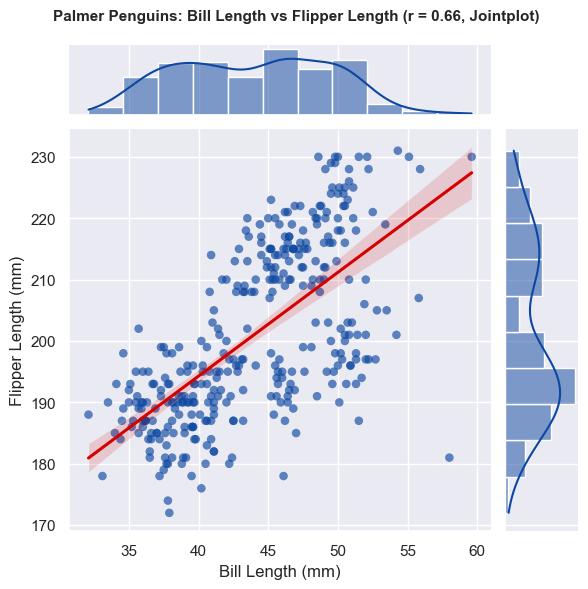

Key Observations:
1. Flipper length and bill length exhibit a strong positive linear relationship (r = 0.656).
2. The marginal histograms demonstrate bimodal distributions, primarily driven by morphological divergence between Gentoo (larger flippers) vs Adelie/Chinstrap penguins.


In [5]:
# Load 'penguins' dataset
try:
    df_penguins = sns.load_dataset("penguins")
except Exception:
    df_penguins = pd.read_csv("penguins.csv")

# Filter out missing records
df_clean = df_penguins.dropna(subset=["bill_length_mm", "flipper_length_mm"])

print("--- 'penguins' Dataset Sample ---")
display(df_clean.head(6))
print(f"Total Valid Observations: {len(df_clean)} across species: {list(df_clean['species'].unique())}")

# Calculate Pearson correlation coefficient & p-value
from scipy import stats
r_val, p_val = stats.pearsonr(df_clean["bill_length_mm"], df_clean["flipper_length_mm"])
print(f"\nPearson Correlation Coefficient (r): {r_val:.3f} (p-value: {p_val:.2e})")

# Visualizing Joint Distribution with OLS Regression Fit
sns.set_theme(style="darkgrid")

g = sns.jointplot(
    data=df_clean,
    x="bill_length_mm",
    y="flipper_length_mm",
    kind="reg",
    color="#0D47A1",
    scatter_kws={"alpha": 0.65, "s": 38, "edgecolor": "none"},
    line_kws={"color": "#D50000", "linewidth": 2.2},
    height=6
)

g.fig.subplots_adjust(top=0.92)
g.fig.suptitle(f"Palmer Penguins: Bill Length vs Flipper Length (r = {r_val:.2f}, Jointplot)", fontsize=11, fontweight="bold")
g.set_axis_labels("Bill Length (mm)", "Flipper Length (mm)")
plt.savefig("penguins_jointplot_regression.png", bbox_inches="tight", dpi=150)
plt.show()

print("Key Observations:")
print(f"1. Flipper length and bill length exhibit a strong positive linear relationship (r = {r_val:.3f}).")
print("2. The marginal histograms demonstrate bimodal distributions, primarily driven by morphological divergence between Gentoo (larger flippers) vs Adelie/Chinstrap penguins.")


---
## 📌 Summary & Key Takeaways

1. **`pairplot`**:
   - The fastest method to explore high-dimensional data, revealing feature distributions, correlations, and cluster separations across categories simultaneously.
2. **`heatmap`**:
   - Essential for 2D matrix exploration, tabular time-series projections, and correlation analysis when paired with `pivot_table()`.
3. **Figure-Level vs Axes-Level Power**:
   - `sns.relplot()` and `sns.catplot()` manage subplots, legends, and aspect ratios automatically via `FacetGrid`, making multi-variable conditioning straightforward.
4. **Statistical Rigor with Confidence Intervals**:
   - Seaborn automatically estimates bootstrap confidence intervals (`errorbar='ci'`), providing visual uncertainty boundaries for group trends and survival rates.
5. **`jointplot` Regression Modeling**:
   - Seamlessly blends bivariate OLS regression modeling with marginal univariate distribution histograms.
